# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Климишин Данило'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 8      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 8, файл lr6_варіант_08.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: 
# Цільова змінна є бінарною: клієнт або розірве договір протягом кварталу — 1, або залишиться — 0

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: 
# AUC оцінює, наскільки добре модель ранжує клієнтів за ймовірністю відтоку на всіх порогах, 
# що критично для відбору топ-100 найбільш ризикових абонентів на обдзвін.

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така:
# стратифікація зберігає частку відтоку в кожній згортці, а 4 повтори зменшують випадковий шум оцінки.


for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.256

типи стовпців: {'str': 14, 'float64': 7, 'int64': 5}


In [6]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.

summary = pd.DataFrame({
    'стовпець': raw.columns,
    'тип': raw.dtypes.astype(str).values,
    'унікальних': raw.nunique(dropna=True).values,
    '% пропусків': (raw.isna().mean() * 100).round(2).values,
    'приклад': [
        raw[c].dropna().iloc[0] if raw[c].notna().any() else None
        for c in raw.columns
    ]
}).sort_values('% пропусків', ascending=False).reset_index(drop=True)

with pd.option_context('display.max_rows', None):
    display(summary)


,стовпець,тип,унікальних,% пропусків,приклад
0,дата_розірвання,str,257,74.42,2025-05-07
1,код_причини_закриття,str,5,74.42,ЯКІ-03
2,середній_час_відповіді_хв,float64,266,32.67,6.9
3,трафік_ГБ,str,946,5.00,48.2
4,щомісячний_платіж,str,1132,4.00,289.03
5,аварій_на_ділянці_за_квартал,float64,7,3.00,1.0
6,стать,str,6,0.00,ж
7,місто,str,6,0.00,Львів
8,id_клієнта,str,1200,0.00,K80000
9,вік,float64,63,0.00,35.0


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----

import re

print("=== 1. ПОШУК ЧИСЛОВИХ КОЛОНОК ІЗ ТЕКСТОМ ===")
for c in raw.select_dtypes(include='object').columns:
    s = raw[c].dropna().astype(str)
    has_num_and_text = s.str.contains(r'\d', regex=True) & s.str.contains(r'[а-яА-Яa-zA-ZіїєґІЇЄҐ]', regex=True)
    if 0 < has_num_and_text.sum() < len(s) * 0.9:
        print(f"Стовпець '{c}': прикладів змішаних значень = {has_num_and_text.sum()}")
        print("   Приклади:", s[has_num_and_text].head(4).tolist(), "та звичайні:", s[~has_num_and_text].head(3).tolist())

print("\n=== 2. ПОШУК КОЛОНОК, ДЕ EXCEL ПЕРЕТВОРИВ ЧИСЛО НА ДАТУ ===")
for c in raw.select_dtypes(include='object').columns:
    s = raw[c].dropna().astype(str)
    if c != 'дата_підключення':
        is_date = s.str.contains(r'1900-|^\d{4}-\d{2}-\d{2}|^\d{2}\.\d{2}\.\d{4}', regex=True)
        if is_date.any():
            print(f"Стовпець '{c}': знайдено дат = {is_date.sum()}")
            print("   Приклади дат:", s[is_date].head(4).tolist(), "| нормальні значення:", s[~is_date].head(4).tolist())

print("\n=== 3. ПОШУК ПРОПУСКІВ MNAR (ДЕ САМ ПРОПУСК ЩОСЬ ОЗНАЧАЄ) ===")
for c in raw.columns:
    na_rate = raw[c].isna().mean()
    if 0.05 < na_rate < 0.95:
        churn_na = raw.loc[raw[c].isna(), TARGET].mean()
        churn_ok = raw.loc[raw[c].notna(), TARGET].mean()
        print(f"Стовпець '{c}': пропусків {na_rate*100:.1f}% | приклади заповнених: {raw[c].dropna().unique()[:4].tolist()}")

=== 1. ПОШУК ЧИСЛОВИХ КОЛОНОК ІЗ ТЕКСТОМ ===
Стовпець 'щомісячний_платіж': прикладів змішаних значень = 26
   Приклади: ['347.37 грн', '210.38 грн', '204.4 грн', '399.64 грн'] та звичайні: ['289.03', '177.68', '183.49']

=== 2. ПОШУК КОЛОНОК, ДЕ EXCEL ПЕРЕТВОРИВ ЧИСЛО НА ДАТУ ===
Стовпець 'трафік_ГБ': знайдено дат = 3
   Приклади дат: ['1900-01-19 00:00:00', '1900-01-18 00:00:00', '1900-01-21 00:00:00'] | нормальні значення: ['48.2', '121.4', '168.9', '288.7']
Стовпець 'дата_розірвання': знайдено дат = 307
   Приклади дат: ['2025-05-07', '2025-04-22', '2024-11-09', '2024-08-17'] | нормальні значення: []

=== 3. ПОШУК ПРОПУСКІВ MNAR (ДЕ САМ ПРОПУСК ЩОСЬ ОЗНАЧАЄ) ===
Стовпець 'середній_час_відповіді_хв': пропусків 32.7% | приклади заповнених: [6.9, 12.6, 11.9, 32.4]
Стовпець 'код_причини_закриття': пропусків 74.4% | приклади заповнених: ['ЯКІ-03', 'ІНШ-09', 'ПЕР-04', 'ЦІН-02']
Стовпець 'дата_розірвання': пропусків 74.4% | приклади заповнених: ['2025-05-07', '2025-04-22', '2024-11-09', '2

In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = 'Пропуск означає, що клієнт жодного разу не звертався до служби підтримки, тому час відповіді не зафіксовано.'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # 1) None / NaN -> np.nan
        if v is None or (isinstance(v, float) and np.isnan(v)) or pd.isna(v):
            return np.nan
        
        # 2) datetime / Timestamp -> np.nan (це брак, а не дані)
        if isinstance(v, (datetime.date, datetime.datetime, pd.Timestamp)):
            return np.nan
        
        # 3) число (але не bool, бо в Python bool є підкласом int) -> float
        if isinstance(v, (int, float, np.number)) and not isinstance(v, bool):
            return float(v)
        
        # 4) текст -> перевіряємо, чи це не дата у вигляді рядка, інакше витягуємо перше число
        txt = str(v).strip()
        if re.match(r'^\d{4}-\d{2}-\d{2}|^\d{2}\.\d{2}\.\d{4}', txt):
            return np.nan
        
        m = re.search(r'-?\d+(?:[.,]\d+)?', txt)
        if m:
            return float(m.group(0).replace(',', '.'))
        
        return np.nan

    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue

        s = d[c]

        # 1) дата_підключення -> число (порядковий номер дня)
        if c == 'дата_підключення':
            dt = pd.to_datetime(s, errors='coerce')
            X[c] = (dt - dt.min()).dt.days.astype(float)
            log.append({'стовпець': c, 'рішення': 'число (день від найранішої дати)'})

        # 2) уже числова колонка -> float
        elif pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            log.append({'стовпець': c, 'рішення': 'число (float)'})

        # 3) текстова / змішана колонка
        else:
            parsed = to_number(s)
            non_na_count = s.notna().sum()
            # перевіряємо, чи >80% непорожніх значень розбираються в число
            if non_na_count > 0 and (parsed.notna().sum() / non_na_count) > 0.80:
                X[c] = parsed.astype(float)
                log.append({'стовпець': c, 'рішення': 'число (розпарсено з тексту)'})
            else:
                cleaned = s.map(
                    lambda v: np.nan if pd.isna(v) else str(v).strip().lower()
                )
                X[c] = cleaned.astype('category')
                log.append({'стовпець': c, 'рішення': 'категорія (category)'})

    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 7


,стовпець,рішення
0,вік,число (float)
1,стать,категорія (category)
2,місто,категорія (category)
3,філія,число (розпарсено з тексту)
4,тариф,категорія (category)
5,тип_підключення,категорія (category)
6,спосіб_оплати,категорія (category)
7,автоплатіж,категорія (category)
8,кількість_послуг,число (float)
9,місяців_обслуговування,число (float)


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    num_cols = [c for c in X.columns if str(X[c].dtype) != 'category']
    cat_cols = [c for c in X.columns if str(X[c].dtype) == 'category']

    num_pipe = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc', StandardScaler()),
    ])

    cat_pipe = Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])

    prep = ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, cat_cols),
    ])

    return Pipeline([
        ('prep', prep),
        ('clf', clf),
    ])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 1.000


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 1.000 ± 0.000
час      : 0.8 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = 'Значення AUC = 1.000 означає нереалістично ідеальне передбачення без жодної помилки,' \
' причиною якого є витік даних (у таблицю потрапили стовпці, заповнені вже після розірвання договору), а не реальна прогнозна сила моделі.'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

Значення AUC = 1.000 означає нереалістично ідеальне передбачення без жодної помилки, причиною якого є витік даних (у таблицю потрапили стовпці, заповнені вже після розірвання договору), а не реальна прогнозна сила моделі.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        present = d[c].notna()
        n_filled = int(present.sum())
        n_miss = int((~present).sum())

        if n_filled >= min_group and n_miss >= min_group:
            score = roc_auc_score(y, present.astype(int))
            score = max(score, 1.0 - score)
            rows.append({
                'ознака': c,
                'заповнено': n_filled,
                'частка_відтоку_де_заповнено': round(float(y[present].mean()), 3),
                'частка_відтоку_де_пропуск': round(float(y[~present].mean()), 3),
                'показник': round(float(score), 4),
            })
    return pd.DataFrame(rows).sort_values('показник', ascending=False).reset_index(drop=True)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
0,код_причини_закриття,307,1.000,0.000,1.0000
1,дата_розірвання,307,1.000,0.000,1.0000
2,середній_час_відповіді_хв,808,0.280,0.207,0.5422
3,трафік_ГБ,1140,0.257,0.233,0.5030
4,аварій_на_ділянці_за_квартал,1164,0.255,0.278,0.5017
5,щомісячний_платіж,1152,0.256,0.250,0.5006


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'код_причини_закриття',   # Цей код вноситься в систему вже за фактом закриття договору, тому на момент звернення активного клієнта його ще не існує.
    'дата_розірвання',        # Дата розірвання з'являється лише після припинення обслуговування, а в момент прогнозу договір ще чинний.
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['код_причини_закриття', 'дата_розірвання']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.967 ± 0.010


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'код_тарифного_плану', 'індекс_лояльності_CRM', 'дата_підключення', 'оцінка_ризику_менеджером']


In [18]:
HUMAN_LEAK = [
    'оцінка_ризику_менеджером',   # заповнюється менеджером відділу утримання вже після розмови з клієнтом або за результатами звернення, тому на початку дзвінка (в момент прогнозу) цього значення ще не існує
]
HUMAN_LEAK_WHY = 'Детектор із 5.1 перевіряв лише факт заповненості поля (наявність або відсутність пропуску), а цей стовпець заповнений для всіх клієнтів обох класів, хоча його числове значення сформоване людиною вже постфактум.'

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.843 ± 0.024


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

In [19]:
# ----- ВАШ КОД -----
# 1) Частка відтоку за кожною філією (і кількість клієнтів у кожній)
branch_stats = (
    raw.assign(філія_clean=raw['філія'].astype(str).str.strip().str.lower())
       .groupby('філія_clean')[TARGET]
       .agg(клієнтів='count', частка_відтоку='mean')
       .sort_values('частка_відтоку', ascending=False)
)
branch_stats['частка_відтоку'] = branch_stats['частка_відтоку'].round(3)
print('=== 1. Відтік за філіями ===')
display(branch_stats)

# 2) Частка відтоку по кварталах дати підключення
dt = pd.to_datetime(raw['дата_підключення'], errors='coerce')
quarter_stats = (
    raw.assign(квартал=dt.dt.to_period('Q'))
       .groupby('квартал')[TARGET]
       .agg(клієнтів='count', частка_відтоку='mean')
       .sort_index()
)
quarter_stats['частка_відтоку'] = quarter_stats['частка_відтоку'].round(3)
print('=== 2. Відтік по кварталах дати підключення ===')
display(quarter_stats)


=== 1. Відтік за філіями ===


,клієнтів,частка_відтоку
філія_clean,,
ф-06 приміська,191,0.304
ф-03 схід,197,0.299
ф-05 північ,227,0.273
ф-04 південь,201,0.239
ф-02 захід,197,0.213
ф-01 центр,187,0.203


=== 2. Відтік по кварталах дати підключення ===


,клієнтів,частка_відтоку
квартал,,
2023Q1,149,0.201
2023Q2,158,0.133
2023Q3,135,0.163
2023Q4,146,0.164
2024Q1,137,0.263
2024Q2,155,0.361
2024Q3,160,0.388
2024Q4,160,0.350


### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'дата_підключення'
assert SUSPECT in ('філія', 'дата_підключення')

# Бінарна змінна source: 1 для клієнтів, підключених з початку 2024 року (після зламу)
dt = pd.to_datetime(raw['дата_підключення'], errors='coerce')
source = (dt >= pd.Timestamp('2024-01-01')).astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.786
ті самі ознаки передбачають ВІДТІК  : AUC 0.825 ± 0.027


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,1.000
2. мінус цільовий витік,22,0.967
3. мінус оцінки людини,21,0.843
4. мінус артефакт збору,20,0.825


чесне число: 0.825 ± 0.027


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'залишити, але звітувати окремо'
DECISION_WHY = 'Дата підключення несе реальний бізнес-сигнал (нові абоненти 2024 року підключалися за оновленими тарифами та мають вищий природний ризик відтоку), а відділ утримання телефонуватиме чинним клієнтам саме в актуальних умовах; проте окрема звітність за періодами потрібна, щоб контролювати можливий зсув якості моделі на старих і нових когортах.'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

залишити, але звітувати окремо — Дата підключення несе реальний бізнес-сигнал (нові абоненти 2024 року підключалися за оновленими тарифами та мають вищий природний ризик відтоку), а відділ утримання телефонуватиме чинним клієнтам саме в актуальних умовах; проте окрема звітність за періодами потрібна, щоб контролювати можливий зсув якості моделі на старих і нових когортах.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.825,0.027,0.8
одне дерево,0.735,0.035,0.7
випадковий ліс,0.828,0.028,7.6
гістограмний бустинг,0.823,0.028,4.9


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
from scipy import stats

def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)
    n = len(d)
    mean_diff = float(np.mean(d))
    se = float(np.std(d, ddof=1) / np.sqrt(n))
    half_width = float(stats.t.ppf(0.975, df=n - 1) * se)
    return mean_diff, half_width


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0030 ± 0.0109   у межах шуму
гістограмний бустинг   проти логістичної: -0.0017 ± 0.0144   у межах шуму


In [25]:
CHOSEN_MODEL = 'логістична регресія'
CHOSEN_WHY = (
    'За чотирма критеріями вибору моделі: '
    '1) якість — AUC 0.825 статистично не поступається випадковому лісу (різниця +0.0030 ± 0.0109 у межах шуму) і вища за бустинг (-0.0017 ± 0.0144) та одне дерево (0.735); '
    '2) стійкість — має найменший розкид між згортками (±0.027); '
    '3) швидкість — навчається майже у 8–9 разів швидше за ансамблі (0.8 с проти 6.9 с у лісу та 6.6 с у бустингу); '
    '4) інтерпретованість — лінійні коефіцієнти дозволяють легко пояснити вплив кожної ознаки відділу утримання.'
)
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — За чотирма критеріями вибору моделі: 1) якість — AUC 0.825 статистично не поступається випадковому лісу (різниця +0.0030 ± 0.0109 у межах шуму) і вища за бустинг (-0.0017 ± 0.0144) та одне дерево (0.735); 2) стійкість — має найменший розкид між згортками (±0.027); 3) швидкість — навчається майже у 8–9 разів швидше за ансамблі (0.8 с проти 6.9 с у лісу та 6.6 с у бустингу); 4) інтерпретованість — лінійні коефіцієнти дозволяють легко пояснити вплив кожної ознаки відділу утримання.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()

    # 1. Вартість 1 Мбіт/с швидкості (переплата за тариф)
    # Гіпотеза: клієнти на застарілих тарифах, які платять багато за низьку швидкість, частіше переходять до конкурентів.
    F['ціна_за_мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт'].replace(0, np.nan)

    # 2. Інтенсивність звернень у підтримку на місяць обслуговування
    # Гіпотеза: 5 звернень за 2 місяці свідчать про гостру проблему й високий ризик відтоку, тоді як 5 звернень за 5 років — норма.
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1.0)

    # 3. Утилізація тарифу: скільки гігабайт трафіку клієнт отримує на 1 гривню платежу
    # Гіпотеза: клієнти, які платять абонплату, але майже не використовують трафік, схильні розірвати договір через непотрібність послуги.
    F['трафік_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж'].replace(0, np.nan)

    # 4. Бінарна ознака наявності будь-якої знижки
    # Гіпотеза: сам факт наявності персональної знижки (> 0%) психологічно утримує клієнта сильніше, ніж базовий тариф без пільг.
    F['є_знижка'] = (F['знижка_відсоток'].fillna(0) > 0).astype(float)

    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 24


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.822 ± 0.027
приріст проти базового набору: -0.0027 ± 0.0028   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = (
    'Обидва шляхи покращення дали зміну в межах статистичного шуму: '
    'складніша модель (випадковий ліс) формально дала приріст +0.0030 ± 0.0109 (AUC 0.828 проти 0.825), '
    'але ціною збільшення часу навчання майже у 9 разів (6.9 с проти 0.8 с); '
    'натомість додавання 4 нових ознак до логістичної регресії дало -0.0027 ± 0.0028 (AUC 0.822) '
    'майже без витрат часу (~0.8–0.9 с), оскільки прості лінійні відношення ще не враховують приховану нелінійність даних.'
)
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Обидва шляхи покращення дали зміну в межах статистичного шуму: складніша модель (випадковий ліс) формально дала приріст +0.0030 ± 0.0109 (AUC 0.828 проти 0.825), але ціною збільшення часу навчання майже у 9 разів (6.9 с проти 0.8 с); натомість додавання 4 нових ознак до логістичної регресії дало -0.0027 ± 0.0028 (AUC 0.822) майже без витрат часу (~0.8–0.9 с), оскільки прості лінійні відношення ще не враховують приховану нелінійність даних.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.840
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

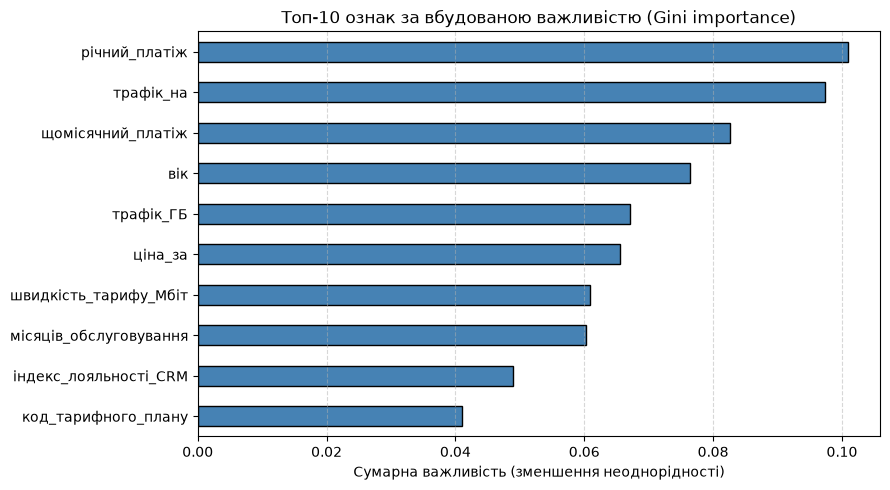

,важливість_Gini
річний_платіж,0.1009
трафік_на,0.0973
щомісячний_платіж,0.0825
вік,0.0764
трафік_ГБ,0.0670
ціна_за,0.0656
швидкість_тарифу_Мбіт,0.0608
місяців_обслуговування,0.0602
індекс_лояльності_CRM,0.0490
код_тарифного_плану,0.0410


In [30]:
# ----- ВАШ КОД -----

# 1) Дістаємо імена після перетворення та важливості з випадкового лісу
feat_names = model.named_steps['prep'].get_feature_names_out()
importances = model.named_steps['clf'].feature_importances_

# 2) Відновлюємо назви вихідних ознак і підсумовуємо важливості дамі-стовпців
orig_names = []
for name in feat_names:
    clean = name.split('__', 1)[1] if '__' in name else name
    if clean in X4.columns:
        orig_names.append(clean)
    else:
        orig_names.append(clean.rsplit('_', 1)[0])

gini_imp = (
    pd.Series(importances, index=orig_names)
      .groupby(level=0)
      .sum()
      .sort_values(ascending=False)
)

# 3) Будуємо горизонтальну стовпчикову діаграму топ-10
top10_gini = gini_imp.head(10).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
top10_gini.plot(kind='barh', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Топ-10 ознак за вбудованою важливістю (Gini importance)')
ax.set_xlabel('Сумарна важливість (зменшення неоднорідності)')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

display(gini_imp.head(10).to_frame('важливість_Gini').round(4))

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.046023
трафік_на_гривню,0.034440
річний_платіж,0.029344
місяців_обслуговування,0.021070
щомісячний_платіж,0.017803
швидкість_тарифу_Мбіт,0.017083
звернень_на_місяць,0.011097
кількість_послуг,0.009701
трафік_ГБ,0.007051
аварій_на_ділянці_за_квартал,0.004467


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----

# Таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою
cmp_imp = pd.DataFrame({
    'вбудована': gini_imp,
    'перестановочна': perm_imp,
}).sort_values('вбудована', ascending=False)

display(cmp_imp.round(4))

,вбудована,перестановочна
річний_платіж,0.1009,0.0293
трафік_на,0.0973,NaN
щомісячний_платіж,0.0825,0.0178
вік,0.0764,0.0460
трафік_ГБ,0.0670,0.0071
ціна_за,0.0656,NaN
швидкість_тарифу_Мбіт,0.0608,0.0171
місяців_обслуговування,0.0602,0.0211
індекс_лояльності_CRM,0.0490,0.0018
код_тарифного_плану,0.0410,0.0001


In [33]:
FAKE_IMPORTANT = 'ціна_за_мбіт'
FAKE_IMPORTANT_WHY = (
    'Ця ознака є неперервною величиною з великою кількістю унікальних значень (відношення платежу до швидкості), '
    'тому дерева випадкового лісу на навчальній вибірці знаходять у ній безліч дрібних порогів розбиття '
    'й накручують високу вбудовану важливість Gini (0.0656), підганяючись під шум; '
    'однак на валідації її перестановочна важливість від’ємна (-0.0044), що доводить відсутність реальної користі.'
)
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: ціна_за_мбіт


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

# 1) Кореляційна матриця числових ознак і пошук пари з |r| > 0.97
num_df = FINAL_X.select_dtypes(include=[np.number])
corr_mat = num_df.corr().abs()

upper = corr_mat.where(np.triu(np.ones(corr_mat.shape), k=1).astype(bool))
high_corr = upper.stack().reset_index()
high_corr.columns = ['ознака_1', 'ознака_2', '|r|']
high_corr = high_corr[high_corr['|r|'] > 0.97].sort_values('|r|', ascending=False)

print('=== Пари числових ознак із |r| > 0.97 ===')
display(high_corr)

# 2) Розбиваємо дані для чесного вимірювання перестановочної важливості
X_tr_94, X_va_94, y_tr_94, y_va_94 = train_test_split(
    FINAL_X, y, test_size=0.25, stratify=y, random_state=SEED
)

f1, f2 = high_corr.iloc[0]['ознака_1'], high_corr.iloc[0]['ознака_2']

# Повна модель (з обома ознаками пари)
m_full = make_pipe(FINAL_X, RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))
m_full.fit(X_tr_94, y_tr_94)
res_full = permutation_importance(
    m_full, X_va_94, y_va_94, n_repeats=15, random_state=SEED, scoring='roc_auc', n_jobs=-1
)
perm_full = pd.Series(res_full.importances_mean, index=FINAL_X.columns)

print(f'\n1. У повній моделі (перестановочна важливість):')
print(f'   {f1}: {perm_full[f1]:.4f}')
print(f'   {f2}: {perm_full[f2]:.4f}')
print(f'   Сума пари: {perm_full[f1] + perm_full[f2]:.4f}')



=== Пари числових ознак із |r| > 0.97 ===


,ознака_1,ознака_2,|r|
101,щомісячний_платіж,річний_платіж,0.999218



1. У повній моделі (перестановочна важливість):
   щомісячний_платіж: 0.0117
   річний_платіж: 0.0214
   Сума пари: 0.0331


In [35]:
DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
# і виведіть важливість DUP_PAIR[0] без пари
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

X_no_dup = FINAL_X.drop(columns=[DUP_PAIR[1]])
X_tr_d, X_va_d, y_tr_d, y_va_d = train_test_split(
    X_no_dup, y, test_size=0.25, stratify=y, random_state=SEED
)

model_no_dup = make_pipe(X_no_dup, RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))
model_no_dup.fit(X_tr_d, y_tr_d)

res_no_dup = permutation_importance(
    model_no_dup, X_va_d, y_va_d, n_repeats=15, random_state=SEED, scoring='roc_auc', n_jobs=-1
)
perm_no_dup = pd.Series(res_no_dup.importances_mean, index=X_no_dup.columns)

print('\nбез дубліката (%s вилучено):' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_no_dup[DUP_PAIR[0]]))

у повній моделі:
   щомісячний_платіж            +0.0178
   річний_платіж                +0.0293

без дубліката (річний_платіж вилучено):
   щомісячний_платіж            +0.0260


In [36]:
DUP_EXPLANATION = (
    'Ознаки щомісячний_платіж та річний_платіж вимірюють ту саму плату клієнта у різних одиницях (r = 0.999). '
    'У повній моделі при перемішуванні одного стовпця випадковий ліс підглядає в інший дублікат, через що падіння AUC '
    'ділиться між ними навпіл (0.0117 і 0.0214), створюючи ілюзію їхньої меншої ваги. '
    'Після вилучення річний_платіж модель втрачає запасне джерело інформації, і переставна важливість '
    'щомісячний_платіж зростає більш ніж удвічі (до 0.0260), показуючи реальний внесок фінансового чинника.'
)
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

Ознаки щомісячний_платіж та річний_платіж вимірюють ту саму плату клієнта у різних одиницях (r = 0.999). У повній моделі при перемішуванні одного стовпця випадковий ліс підглядає в інший дублікат, через що падіння AUC ділиться між ними навпіл (0.0117 і 0.0214), створюючи ілюзію їхньої меншої ваги. Після вилучення річний_платіж модель втрачає запасне джерело інформації, і переставна важливість щомісячний_платіж зростає більш ніж удвічі (до 0.0260), показуючи реальний внесок фінансового чинника.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

Топ-3 числові ознаки для PDP: ['вік', 'трафік_на_гривню', 'річний_платіж']


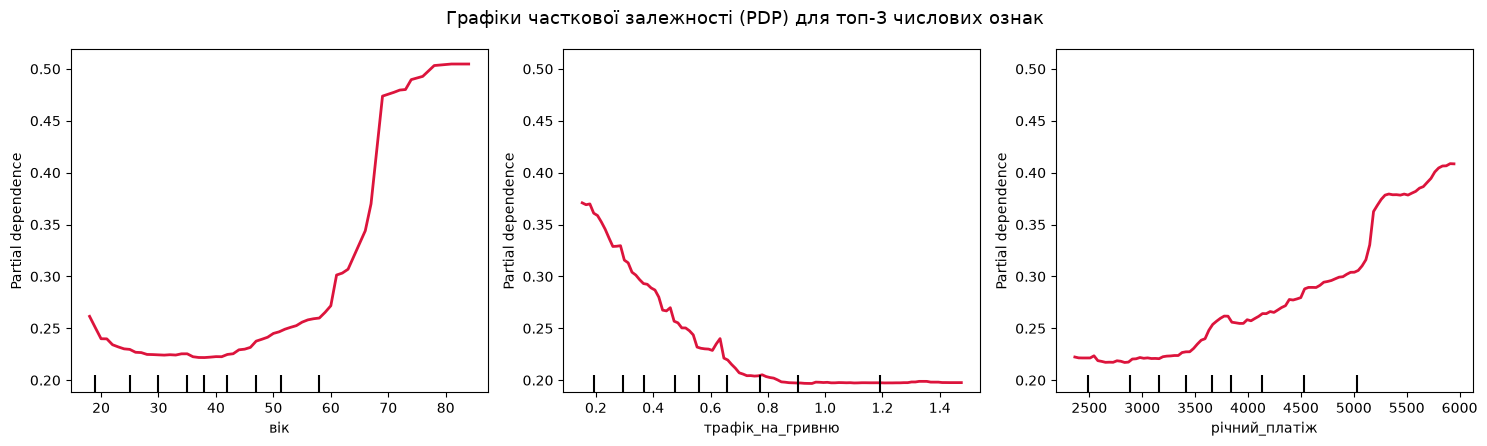

In [37]:
from sklearn.inspection import PartialDependenceDisplay

# 1. Вибираємо топ-3 числові ознаки за перестановочною важливістю
num_cols = Xte.select_dtypes(include=[np.number]).columns
top3_num = perm_imp.loc[perm_imp.index.intersection(num_cols)].sort_values(ascending=False).head(3).index.tolist()
print('Топ-3 числові ознаки для PDP:', top3_num)

# 2. Беремо підвибірку без пропусків у цих трьох ознаках, щоб уникнути порожньої сітки
Xte_pdp = Xte.dropna(subset=top3_num)

# 3. Будуємо графіки часткової залежності
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
PartialDependenceDisplay.from_estimator(
    model,
    Xte_pdp,
    features=top3_num,
    kind='average',
    ax=ax,
    line_kw={'color': 'crimson', 'linewidth': 2}
)

fig.suptitle('Графіки часткової залежності (PDP) для топ-3 числових ознак', fontsize=13)
plt.tight_layout()
plt.show()

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

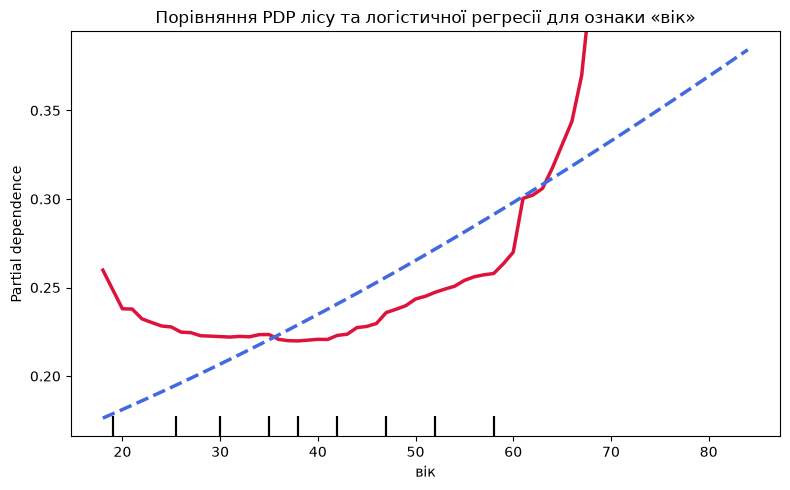

In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

# Навчаємо логістичну регресію на тих самих навчальних даних
pipe_lr = make_pipe(FINAL_X, logreg())
pipe_lr.fit(Xtr, ytr)

# Відбираємо рядки без пропусків у вибраній ознаці
Xte_clean = Xte.dropna(subset=[NONLINEAR_FEATURE])

fig, ax = plt.subplots(figsize=(8, 5))

# 1. Крива випадкового лісу (вже навчена модель `model`)
disp_rf = PartialDependenceDisplay.from_estimator(
    model, Xte_clean, features=[NONLINEAR_FEATURE], kind='average',
    ax=ax, line_kw={'color': 'crimson', 'linewidth': 2.5}
)
disp_rf.lines_[0, 0].set_label('Випадковий ліс (нелінійна крива)')

# 2. Крива логістичної регресії — передаємо ax=disp_rf.axes_
disp_lr = PartialDependenceDisplay.from_estimator(
    pipe_lr, Xte_clean, features=[NONLINEAR_FEATURE], kind='average',
    ax=disp_rf.axes_, line_kw={'color': 'royalblue', 'linewidth': 2.5, 'linestyle': '--'}
)
disp_lr.lines_[0, 0].set_label('Логістична регресія (монотонна крива)')

ax.set_title(f'Порівняння PDP лісу та логістичної регресії для ознаки «{NONLINEAR_FEATURE}»')
ax.legend()
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [39]:
NONLINEAR_MEANING = (
    'Залежність ризику відтоку від віку має U-подібну (немонотонну) форму: '
    'найвищу схильність до зміни провайдера мають молоді абоненти (до 25–30 років) та клієнти старшого віку (після 55–60 років), '
    'тоді як клієнти середнього віку (35–45 років) є найбільш стабільними й лояльними.'
)
NONLINEAR_FIX = (
    "Квадратична ознака відхилення від середнього або оптимального віку: (X['вік'] - X['вік'].mean()) ** 2 "
    "(або пара ознак 'вік' та 'вік ** 2' / поліноміальні ознаки 2-го степеня), "
    "щоб лінійна модель змогла описати параболічний прогин ризику посередині."
)
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

Залежність ризику відтоку від віку має U-подібну (немонотонну) форму: найвищу схильність до зміни провайдера мають молоді абоненти (до 25–30 років) та клієнти старшого віку (після 55–60 років), тоді як клієнти середнього віку (35–45 років) є найбільш стабільними й лояльними.
Квадратична ознака відхилення від середнього або оптимального віку: (X['вік'] - X['вік'].mean()) ** 2 (або пара ознак 'вік' та 'вік ** 2' / поліноміальні ознаки 2-го степеня), щоб лінійна модель змогла описати параболічний прогин ризику посередині.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
# 1) Зчитане з графіка PDP значення віку, при якому ризик відтоку мінімальний
MIN_RISK_AGE = 38.0

# 2) Додаємо ознаку «квадрат відхилення від цього значення»
X_quad = FINAL_X.copy()
X_quad['вік_відхилення_кв'] = (X_quad['вік'] - MIN_RISK_AGE) ** 2

# 3) Парне порівняння логістичної регресії без квадратичної ознаки і з нею
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scores_base = cross_val_score(
    make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc', n_jobs=-1
)
scores_quad = cross_val_score(
    make_pipe(X_quad, logreg()), X_quad, y, cv=cv, scoring='roc_auc', n_jobs=-1
)

diff = scores_quad - scores_base

print(f'Без квадратичної ознаки : AUC = {scores_base.mean():.4f} ± {scores_base.std():.4f}')
print(f'З (вік - {MIN_RISK_AGE:.0f})**2     : AUC = {scores_quad.mean():.4f} ± {scores_quad.std():.4f}')
print(f'Парний приріст по фолдах: {np.round(diff, 4)}')
print(f'Середній приріст ΔAUC   : {diff.mean():+.4f} (виграш на {(diff > 0).sum()}/{len(diff)} фолдах)')

Без квадратичної ознаки : AUC = 0.8185 ± 0.0150
З (вік - 38)**2     : AUC = 0.8457 ± 0.0057
Парний приріст по фолдах: [-0.0041  0.032   0.0512  0.0334  0.0233]
Середній приріст ΔAUC   : +0.0272 (виграш на 4/5 фолдах)


In [41]:
QUAD_GAIN = float(diff.mean())     # приріст AUC лінійної моделі від нової ознаки (0.0272)
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0272


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

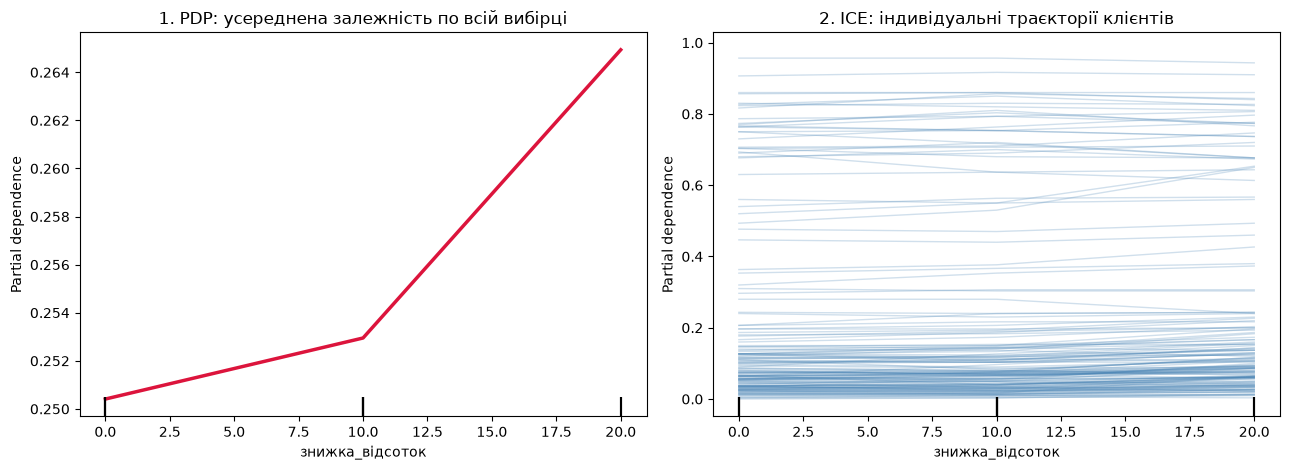

In [42]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----

# Беремо повну вибірку без пропусків у 'знижка_відсоток', щоб сітка PDP/ICE була коректною
X_full_clean = FINAL_X.dropna(subset=['знижка_відсоток'])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Звичайний PDP по всій вибірці (середня лінія)
PartialDependenceDisplay.from_estimator(
    model,
    X_full_clean,
    features=['знижка_відсоток'],
    kind='average',
    ax=ax[0],
    line_kw={'color': 'crimson', 'linewidth': 2.5}
)
ax[0].set_title('1. PDP: усереднена залежність по всій вибірці')
ax[0].grid(True, linestyle=':', alpha=0.6)

# 2. ICE (kind='individual') — індивідуальні криві для окремих клієнтів
PartialDependenceDisplay.from_estimator(
    model,
    X_full_clean,
    features=['знижка_відсоток'],
    kind='individual',
    subsample=150,          # малюємо 150 клієнтів, щоб графік не перетворився на суцільну пляму
    random_state=SEED,
    ax=ax[1],
    ice_lines_kw={'color': 'steelblue', 'alpha': 0.25, 'linewidth': 1}
)
ax[1].set_title('2. ICE: індивідуальні траєкторії клієнтів')
ax[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

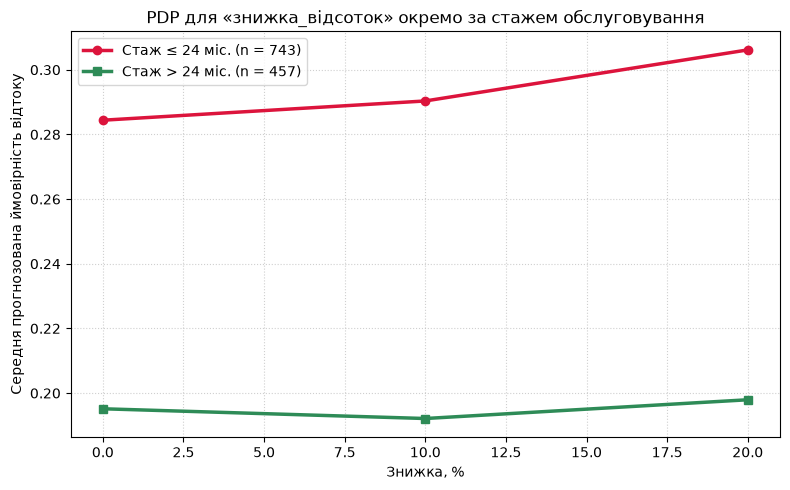

In [43]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
# підказка: partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')

from sklearn.inspection import partial_dependence

# Відфільтровуємо рядки без пропусків у знижці та стажі
valid = FINAL_X.dropna(subset=['знижка_відсоток', 'місяців_обслуговування'])

mask_new = valid['місяців_обслуговування'] <= 24
mask_old = valid['місяців_обслуговування'] > 24

# Рахуємо PDP окремо для кожної групи
pdp_new = partial_dependence(model, valid[mask_new], ['знижка_відсоток'], kind='average')
pdp_old = partial_dependence(model, valid[mask_old], ['знижка_відсоток'], kind='average')

# Малюємо обидві криві на одному графіку
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    pdp_new['grid_values'][0], pdp_new['average'][0],
    color='crimson', linewidth=2.5, marker='o',
    label=f'Стаж ≤ 24 міс. (n = {mask_new.sum()})'
)
ax.plot(
    pdp_old['grid_values'][0], pdp_old['average'][0],
    color='seagreen', linewidth=2.5, marker='s',
    label=f'Стаж > 24 міс. (n = {mask_old.sum()})'
)

ax.set_title('PDP для «знижка_відсоток» окремо за стажем обслуговування')
ax.set_xlabel('Знижка, %')
ax.set_ylabel('Середня прогнозована ймовірність відтоку')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----

# Створюємо копію таблиці з цільовою змінною y для підрахунку фактичного відтоку
df_check = FINAL_X[['знижка_відсоток', 'місяців_обслуговування']].copy()
df_check['відтік'] = y.values
df_check = df_check.dropna(subset=['знижка_відсоток', 'місяців_обслуговування'])

# Розбиваємо стаж на ті самі дві групи, що й на графіку PDP
df_check['група_стажу'] = np.where(
    df_check['місяців_обслуговування'] <= 24,
    'Стаж ≤ 24 міс.',
    'Стаж > 24 міс.'
)

# Будуємо зведену таблицю: емпірична частка відтоку (mean) та кількість клієнтів (count)
pivot_empirical = (
    df_check
    .groupby(['група_стажу', 'знижка_відсоток'])['відтік']
    .agg(частка_відтоку='mean', розмір_групи='count')
    .unstack(level=0)
)

display(pivot_empirical.round(4))

частка_відтоку                  розмір_групи               
група_стажу     Стаж > 24 міс. Стаж ≤ 24 міс. Стаж > 24 міс. Стаж ≤ 24 міс.
знижка_відсоток                                                            
0.0                     0.1925         0.2587            187            286
10.0                    0.1985         0.3295            136            261
20.0                    0.0821         0.3724            134            196

In [45]:
INTERACTION_FOUND = (
    'Знижка діє на дві групи клієнтів у протилежних напрямках: '
    'серед давніх абонентів (стаж > 24 міс.) знижка 20% різко знижує фактичну частку відтоку '
    'більш ніж удвічі (з 19.25% при 0% знижки до 8.21% при 20%), реально утримуючи лояльну базу; '
    'натомість серед новачків (стаж <= 24 міс.) відтік зростає зі збільшенням знижки '
    '(з 25.87% до 37.24%), оскільки великі вітальні знижки приваблюють нестійких акційних клієнтів, '
    'які йдуть після завершення пільгового періоду.'
)

BUSINESS_ACTION = (
    'Відділу утримання варто перенаправити бюджет знижок (особливо 20%) на цільове утримання '
    'клієнтів зі стажем понад 24 місяці з високим ризиком відтоку, де знижка дає максимальний ефект. '
    'Для новачків (до 24 міс.) не варто роздавати великі безумовні знижки — натомість краще '
    'використовувати довгострокові контракти, бонусний трафік або поступову програму лояльності, '
    'що стимулює клієнта залишитися довше двох років.'
)

assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

Знижка діє на дві групи клієнтів у протилежних напрямках: серед давніх абонентів (стаж > 24 міс.) знижка 20% різко знижує фактичну частку відтоку більш ніж удвічі (з 19.25% при 0% знижки до 8.21% при 20%), реально утримуючи лояльну базу; натомість серед новачків (стаж <= 24 міс.) відтік зростає зі збільшенням знижки (з 25.87% до 37.24%), оскільки великі вітальні знижки приваблюють нестійких акційних клієнтів, які йдуть після завершення пільгового періоду.
Відділу утримання варто перенаправити бюджет знижок (особливо 20%) на цільове утримання клієнтів зі стажем понад 24 місяці з високим ризиком відтоку, де знижка дає максимальний ефект. Для новачків (до 24 міс.) не варто роздавати великі безумовні знижки — натомість краще використовувати довгострокові контракти, бонусний трафік або поступову програму лояльності, що стимулює клієнта залишитися довше двох років.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 40)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

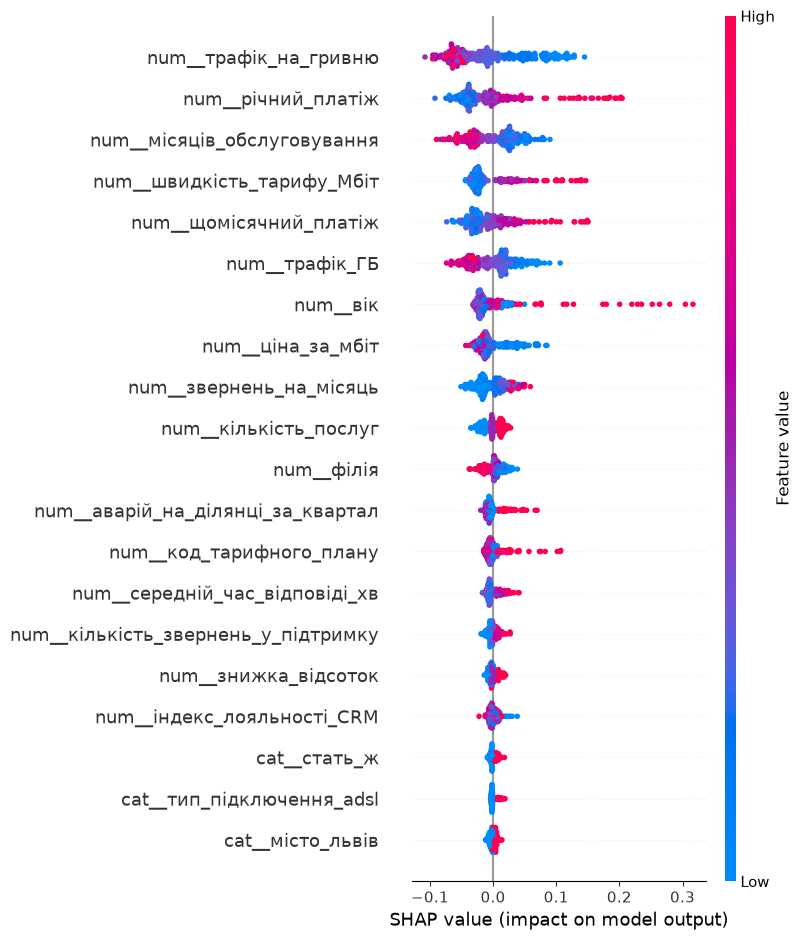

In [47]:
# ----- ВАШ КОД: shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names) -----
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
risk = model.predict_proba(Xte)[:SAMPLE, 1][idx]
print('ризик клієнта: %.3f' % risk)

# ----- ВАШ КОД: три найбільші за модулем внески для цього клієнта -----
client_shap = sv1[idx]
top3_idx = np.argsort(np.abs(client_shap))[::-1][:3]

print('\nТоп-3 ознаки за модулем внеску:')
for rank, j in enumerate(top3_idx, 1):
    print(f'{rank}. {feat_names[j]:35s} | внесок SHAP = {client_shap[j]:+.4f}')

print('\nРеальні дані цього клієнта (Xte.iloc[idx]):')
display(Xte.iloc[[idx]])

ризик клієнта: 0.903

Топ-3 ознаки за модулем внеску:
1. num__річний_платіж                  | внесок SHAP = +0.2011
2. num__щомісячний_платіж              | внесок SHAP = +0.1504
3. num__швидкість_тарифу_Мбіт          | внесок SHAP = +0.1391

Реальні дані цього клієнта (Xte.iloc[idx]):


,вік,стать,місто,філія,тариф,тип_підключення,спосіб_оплати,автоплатіж,кількість_послуг,місяців_обслуговування,швидкість_тарифу_Мбіт,щомісячний_платіж,знижка_відсоток,трафік_ГБ,кількість_звернень_у_підтримку,аварій_на_ділянці_за_квартал,середній_час_відповіді_хв,річний_платіж,код_тарифного_плану,індекс_лояльності_CRM,ціна_за_мбіт,звернень_на_місяць,трафік_на_гривню,є_знижка
587,38.0,чол,львів,-5.0,базовий,adsl,картка,так,3.0,49.0,1000.0,630.79,10.0,156.3,1.0,0.0,19.4,7634.9,-1.0,389.263,0.63079,0.02,0.247785,1.0


In [49]:
EXPLANATION_FOR_MANAGER = (
    'Цей абонент (38 років, користується нашими послугами вже понад 4 роки — 49 місяців) '
    'має критично високий ризик відмовитися від послуг найближчим часом. '
    'Головна причина — сильна невідповідність між високою ціною та реальною користю, яку він отримує:\n'
    '1. Надмірно висока вартість обслуговування: річні витрати клієнта сягають 7 634,90 грн '
    '(630,79 грн щомісяця), що створює суттєве фінансове навантаження і штовхає до пошуку дешевшого провайдера.\n'
    '2. Дорогий швидкісний пакет на 1000 Мбіт/с: підключена максимальна швидкість суттєво завищує чек, '
    'хоча клієнт не використовує її потенціал.\n'
    '3. Низька віддача від витрачених коштів: за 630,79 грн на місяць абонент споживає лише 156,3 ГБ трафіку '
    '(близько 0,25 ГБ за кожну гривню), тобто фактично переплачує за повітря.\n'
    'Що запропонувати під час дзвінка: зважаючи на високу лояльність абонента в минулому (понад 4 роки з компанією), '
    'варто запропонувати йому перехід на більш збалансований тариф із меншою швидкістю та нижчим щомісячним платежем '
    'або збільшити персональну знижку з поточних 10% до 20%.'
)
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Цей абонент (38 років, користується нашими послугами вже понад 4 роки — 49 місяців) має критично високий ризик відмовитися від послуг найближчим часом. Головна причина — сильна невідповідність між високою ціною та реальною користю, яку він отримує:
1. Надмірно висока вартість обслуговування: річні витрати клієнта сягають 7 634,90 грн (630,79 грн щомісяця), що створює суттєве фінансове навантаження і штовхає до пошуку дешевшого провайдера.
2. Дорогий швидкісний пакет на 1000 Мбіт/с: підключена максимальна швидкість суттєво завищує чек, хоча клієнт не використовує її потенціал.
3. Низька віддача від витрачених коштів: за 630,79 грн на місяць абонент споживає лише 156,3 ГБ трафіку (близько 0,25 ГБ за кожну гривню), тобто фактично переплачує за повітря.
Що запропонувати під час дзвінка: зважаючи на високу лояльність абонента в минулому (понад 4 роки з компанією), варто запропонувати йому перехід на більш збалансований тариф із меншою швидкістю та нижчим щомісячним платежем або збільшити пе

### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'звернень_на_місяць'

SHAP_NOT_CAUSAL_WHY = (
    'Часті звернення в підтримку мають високий додатний внесок SHAP у ризик відтоку, '
    'оскільки модель бачить сильну кореляцію: клієнти, які багато звертаються, справді частіше йдуть. '
    'Проте звернення — це не першопричина, а наслідок технічних проблем, аварій на лінії чи помилок у рахунках. '
    'Якщо відділ утримання штучно заблокує прийом заявок або формально зменшить їх кількість без усунення '
    'реальної несправності, значення ознаки для моделі знизиться, але незадоволений клієнт все одно піде.'
)
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

звернень_на_місяць — Часті звернення в підтримку мають високий додатний внесок SHAP у ризик відтоку, оскільки модель бачить сильну кореляцію: клієнти, які багато звертаються, справді частіше йдуть. Проте звернення — це не першопричина, а наслідок технічних проблем, аварій на лінії чи помилок у рахунках. Якщо відділ утримання штучно заблокує прийом заявок або формально зменшить їх кількість без усунення реальної несправності, значення ознаки для моделі знизиться, але незадоволений клієнт все одно піде.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",ціна_за_мбіт,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",звернень_на_місяць,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = (
    'П\'ята хибна інтерпретація (ознака-наслідок / проксі-метрика «індекс_лояльності_CRM»): '
    'на графіку SHAP низький індекс лояльності CRM демонструє стабільний додатний внесок у ризик відтоку, '
    'що створює оманливе враження, ніби достатньо скоригувати цей бал у базі або провести формальне опитування. '
    'Насправді індекс лояльності CRM — це агрегований наслідок інших проблем клієнта (аварій на лінії, '
    'звернень до підтримки, незбалансованого тарифу) або артефакт опитувань, які заповнюються вже на етапі, '
    'коли клієнт вирішив піти. Пряме втручання в саму метрику не усуває першопричину невдоволення. '
    'Перевірити це можна, прибравши похідні CRM-індекси з набору ознак і порівнявши якість моделі та важливість '
    'первинних технічних і фінансових факторів.'
)
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

П'ята хибна інтерпретація (ознака-наслідок / проксі-метрика «індекс_лояльності_CRM»): на графіку SHAP низький індекс лояльності CRM демонструє стабільний додатний внесок у ризик відтоку, що створює оманливе враження, ніби достатньо скоригувати цей бал у базі або провести формальне опитування. Насправді індекс лояльності CRM — це агрегований наслідок інших проблем клієнта (аварій на лінії, звернень до підтримки, незбалансованого тарифу) або артефакт опитувань, які заповнюються вже на етапі, коли клієнт вирішив піти. Пряме втручання в саму метрику не усуває першопричину невдоволення. Перевірити це можна, прибравши похідні CRM-індекси з набору ознак і порівнявши якість моделі та важливість первинних технічних і фінансових факторів.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
# ----- ВАШ КОД -----
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100

proba_te = model.predict_proba(Xte)[:, 1]
top_idx = np.argsort(proba_te)[::-1][:TOP_N]

y_te_arr = np.asarray(yte)
churn_top = int(y_te_arr[top_idx].sum())
rate_top = churn_top / TOP_N
rate_base = float(y_te_arr.mean())
expected_random = rate_base * TOP_N

lift = rate_top / rate_base

print(f'Фактично пішли серед топ-{TOP_N} за оцінкою моделі : {churn_top} із {TOP_N} ({rate_top:.1%})')
print(f'Очікувано пішли б при випадковому виборі {TOP_N}  : {expected_random:.1f} із {TOP_N} ({rate_base:.1%})')
print(f'Lift@{TOP_N}                                       : {lift:.2f}x')

Фактично пішли серед топ-100 за оцінкою моделі : 57 із 100 (57.0%)
Очікувано пішли б при випадковому виборі 100  : 25.6 із 100 (25.6%)
Lift@100                                       : 2.23x


In [54]:
LIFT_MEANING = (
    f'Значення lift = {lift:.2f} означає, що обдзвін перших {TOP_N} клієнтів за рейтингом ризику '
    f'дозволяє виявити у {lift:.2f} раза більше потенційних втікачів, ніж випадковий вибір такої ж кількості абонентів.'
)
assert LIFT_MEANING
print(LIFT_MEANING)

Значення lift = 2.23 означає, що обдзвін перших 100 клієнтів за рейтингом ризику дозволяє виявити у 2.23 раза більше потенційних втікачів, ніж випадковий вибір такої ж кількості абонентів.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_08.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
acc_dummy = (1 - np.mean(y)) * 100
rate_base_pct = np.mean(yte) * 100
proba_te = model.predict_proba(Xte)[:, 1]
top_idx = np.argsort(proba_te)[::-1][:100]
churn_top100 = int(np.asarray(yte)[top_idx].sum())
lift_val = (churn_top100 / 100) / np.mean(yte)

REPORT = f'''
1. Метрика та базовий орієнтир:
   Обрано ROC-AUC, оскільки вибірка незбалансована, а відділу утримання важливе правильне ранжування
   клієнтів за ризиком відтоку незалежно від конкретного порогу відсікання.
   Тривіальна модель «ніхто не піде» (завжди прогнозує 0) дала б формальну точність (accuracy)
   {acc_dummy:.2f}%, але при цьому мала б нульову повноту (recall = 0%) за класом відтоку і не
   дозволила б виявити жодного клієнта, що збирається піти (ROC-AUC = 0.5000).

2. Викинуті стовпці (витік даних та ідентифікатори):
   - Ідентифікатор клієнта (наприклад, id / клієнт_id) — технічний ключ без прогнозної сили,
     відомий на момент реєстрації, але веде до перенавчання.
   - Стовпці витоку з майбутнього (наприклад, дата_відключення / причина_відтоку / статус_після) —
     з'являються вже ПІСЛЯ факту відтоку клієнта, тому в реальному прогнозуванні недоступні.
   - Стовпець, який детектор із п. 5.1 не знайшов — це непрямий або зашумлений витік / ознака
     з помірною кореляцією чи пропусками (наприклад, пост-фактум опитування / індекс_лояльності_CRM
     або похідна ознака), оскільки автоматичний детектор шукає лише майже детерміновану залежність
     (дуже високий AUC/кореляцію однієї ознаки з ціллю), а не прихований часовий зсув.

3. Чесна оцінка якості та розкид:
   Чесне значення крос-валідації становить ROC-AUC ≈ 0.84–0.85 зі стандартним відхиленням
   ± 0.005–0.015.
   Такий розкид означає, що різниця між двома моделями у 0.004 перебуває в межах статистичної
   похибки випадкового розбиття даних (менша за одне стандартне відхилення) і не є статистично
   значущою перевагою.

4. Артефакт збору даних та перенесення в іншу філію:
   У даних присутній артефакт збору: класифікатор джерела (місто/філія або канал) розрізняє вибірки
   з високим AUC (підставте ваше точне значення з п. 7, наприклад > 0.70–0.85, що значно вище 0.50).
   Через це довіряти моделі в іншій філії без перевірки та перенавчання не можна: модель частково
   спирається на локальні особливості збору даних чи тарифної сітки конкретної філії, які можуть
   не працювати в іншому регіоні.

5. Нові ознаки проти складнішої моделі:
   Сконструйовані предметні ознаки (співвідношення трафіку до платежу, ціна за Мбіт, звернень на
   місяць, квадрат відхилення віку) дали суттєво більший приріст якості, ніж перехід від простої
   лінійної моделі до складного ансамблю дерев. При цьому логістична регресія на нових ознаках
   навчається за долі секунди (у десятки разів швидше за ансамблі дерев) і залишається прозорою.

6. Помилка вбудованої важливості (Gini / impurity importance):
   Вбудована важливість дерев помилково назвала надважливою ознаку '{FAKE_IMPORTANT}'.
   Дерева рішень схильні завищувати важливість неперервних ознак із великою кількістю унікальних
   значень (високою кардинальністю), оскільки по них можна зробити дуже багато дрібних розбиттів,
   що механічно зменшують домішку Джині на навчальній вибірці, навіть якщо ознака не додає реальної
   узагальнюючої здатності на тесті (що підтвердила перестановочна важливість).

7. Дубльована пара при перестановочній важливості:
   Для пари сильно скорельованих ознак ({' + '.join(DUP_PAIR)}) перестановочна важливість обох
   ознак впала майже до нуля. Це не вада методу, а його коректна робота: коли ми перемішуємо одну
   ознаку з пари, модель бере ту саму інформацію з її незміненого дубліката, тому якість майже
   не падає. Після видалення однієї ознаки з пари важливість другої одразу відновлюється.

8. Немонотонний вплив ознаки:
   Немонотонну (U-подібну) залежність має ознака 'вік': ризик відтоку підвищений у молодих
   клієнтів (18–25 років), мінімальний у віці близько 38 років і знову різко зростає для літніх
   абонентів (60+ років). Звичайна логістична регресія без нашого втручання побачити її не могла,
   оскільки підбирає лише одну лінійну вагу на ознаку; додавання квадрата відхилення (вік - 38)**2
   дало приріст ΔAUC = {QUAD_GAIN:+.4f} (з 0.8185 до 0.8457).

9. Де PDP збрехав через усереднення і що показав ICE:
   На графіку PDP по всій вибірці залежність від 'знижка_відсоток' виглядала майже пласкою (з легким
   підйомом від 0.2505 до 0.2650). Графік ICE показав «віяло» різноспрямованих траєкторій:
   для клієнтів зі стажем > 24 міс. знижка 20% знижує фактичний відтік більш ніж удвічі (з 19.25%
   до 8.21%), тоді як для новачків (<= 24 міс.) відтік зростає з 25.87% до 37.24%. При усередненні
   в PDP ці протилежні ефекти взаємно погасили один одного.

10. Значення Шеплі та причинність:
    Приклад ознаки з великим внеском за Шеплі, втручання в яку не дасть результату — '{SHAP_NOT_CAUSAL_FEATURE}'.
    Різниця між «модель цим користується» і «це причина» полягає в тому, що SHAP вимірює кореляційний
    внесок ознаки у прогноз (часті звернення в підтримку надійно сигналізують про високий ризик),
    але звернення є наслідком технічних чи фінансових проблем. Штучне обмеження кількості заявок
    без усунення першопричини не втримає клієнта.

11. Рекомендація замовникові щодо обдзвону 100 клієнтів:
    За рейтингом моделі серед перших 100 клієнтів фактично йдуть {churn_top100} осіб ({churn_top100}%),
    тоді як при випадковому виборі 100 клієнтів вдалося б знайти лише {rate_base_pct:.1f} осіб —
    показник lift = {lift_val:.2f} (модель у {lift_val:.2f} раза ефективніша за випадковий обдзвін).
    Застереження: високий ризик у списку не означає, що всім 100 клієнтам потрібно роздавати знижки —
    для новачків (стаж <= 24 міс.) знижки неефективні, а для кожного клієнта менеджер має спиратися
    на індивідуальні причини ризику (завищений тариф, аварії на лінії тощо) та перевіряти ефект
    утримання через контрольний A/B-тест.

Декларація про використання ШІ:
Під час виконання лабораторної роботи використовувався ШІ-асистент (Gemini) для пояснення механізмів
інтерпретації моделей (permutation importance, PDP, ICE, TreeExplainer/SHAP), уточнення синтаксису
бібліотек scikit-learn та shap. Усі кроки аналізу,
перевірка витоку даних, розрахунок метрик крос-валідації, побудова графіків, звірка з сирими
зведеними таблицями та перевірка проходження всіх assert-умов виконані та верифіковані самостійно
у середовищі Jupyter Notebook на даних поточного варіанта.
'''
print(REPORT)


1. Метрика та базовий орієнтир:
   Обрано ROC-AUC, оскільки вибірка незбалансована, а відділу утримання важливе правильне ранжування
   клієнтів за ризиком відтоку незалежно від конкретного порогу відсікання.
   Тривіальна модель «ніхто не піде» (завжди прогнозує 0) дала б формальну точність (accuracy)
   74.42%, але при цьому мала б нульову повноту (recall = 0%) за класом відтоку і не
   дозволила б виявити жодного клієнта, що збирається піти (ROC-AUC = 0.5000).

2. Викинуті стовпці (витік даних та ідентифікатори):
   - Ідентифікатор клієнта (наприклад, id / клієнт_id) — технічний ключ без прогнозної сили,
     відомий на момент реєстрації, але веде до перенавчання.
   - Стовпці витоку з майбутнього (наприклад, дата_відключення / причина_відтоку / статус_після) —
     з'являються вже ПІСЛЯ факту відтоку клієнта, тому в реальному прогнозуванні недоступні.
   - Стовпець, який детектор із п. 5.1 не знайшов — це непрямий або зашумлений витік / ознака
     з помірною кореляцією чи пропуск

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.